# Salary Prediction

Corresponding  with this notebook is a slide deck where you will need to update all the portions in red.  Completing the notebook will provide all the results needed for the slides.  **Correctly completing the slides is a required part of the project.**


## Table of Contents
- [Introduction](#intro)
- [Part I - Descriptive Statistics](#descriptive)
- [Part II - Regression](#regression)
- [Part III - Interpret Results](#interpret)


<a id='intro'></a>
### Introduction

Linear Regression is very commonly performed by data analysts and data scientists.  For this project, you will be working to understand the results of a Linear Regression model associated with salaries.  Your goal is to work through this notebook to understand what variables are related to salary, and how exactly they are related.

As a final check, assure you meet all the criteria on the rubric.

<a id='descriptive'></a>
#### Part I - Descriptive Statistics

To get started, let's import our libraries.

In [39]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import seaborn as sb
from patsy import dmatrices

random.seed(0)

For each of the parts of question `1` notice links to [pandas documentation](https://pandas.pydata.org/) is provided to assist with answering the questions.  Though there are other ways you could solve the questions, the documentation is provided to assist you with one fast way to find the answer to each question.


`1.a)` Now, read in the `salary_data.csv` data. Store it in `df`. Read in the dataset and take a look at the top few rows here. **This question is completed for you**:

In [40]:
df = pd.read_csv("data/salary_data.csv")
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


`b)` Use the below cell to find the number of rows in the dataset. [Helpful pandas link - `Dataframe.shape`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html#pandas.DataFrame.shape)

In [41]:
print(f"rows: {len(df)}")

rows: 375


`c)` Do any of the rows have missing values? [Helpful Pandas Link One](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html) and [Helpful Pandas Link Two](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html)  

If there are missing values, determine a method for dealing with them.

In [42]:
print(df.isna().any())
print(df[df.isna().any(axis=1)].head())

Age                    True
Gender                 True
Education Level        True
Job Title              True
Years of Experience    True
Salary                 True
dtype: bool
     Age Gender Education Level Job Title  Years of Experience  Salary
172  NaN    NaN             NaN       NaN                  NaN     NaN
260  NaN    NaN             NaN       NaN                  NaN     NaN


In [43]:
# all rows containing NaN values are completely empty, no data will be lost if dropped
# dropping and re-indexing as index seems to just be a row counter, not captured data
# adjusting column names to make them easier to work with
df.dropna(inplace=True, ignore_index=True)
df.rename(columns={
    "Age": "age",
    "Gender": "gender", 
    "Education Level": "education_level",
    "Job Title": "job_title",
    "Years of Experience": "years_experience",
    "Salary": "salary"}, inplace=True)
print(df.isna().any())
print(f"rows: {len(df)}")

age                 False
gender              False
education_level     False
job_title           False
years_experience    False
salary              False
dtype: bool
rows: 373


`d)` How many employees are in each `education_level`? Build a bar chart to show the count of employees in each level.

In [44]:
df["education_level"].value_counts()

education_level
Bachelor's    224
Master's       98
PhD            51
Name: count, dtype: int64

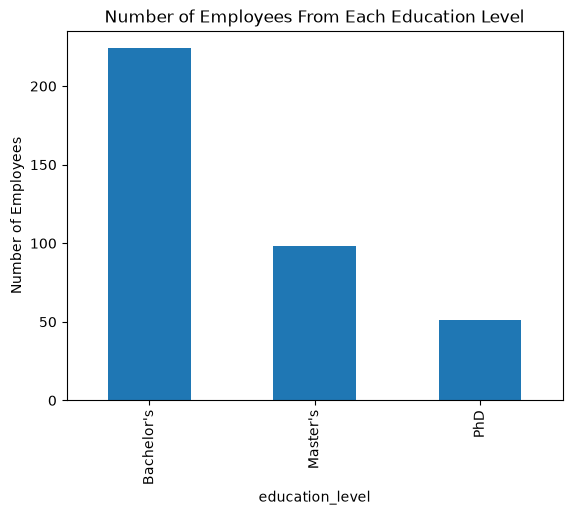

In [45]:
# bar chart of results - this part is done for you
df["education_level"].value_counts().plot(kind="bar")
plt.title("Number of Employees From Each Education Level")
plt.ylabel("Number of Employees")
plt.show()

`e)` What are the possible values for `salary`?  What does the distribution of `salary` look like?

In [46]:
# print(df["salary"].value_counts())
print("salary:")
print(f"unique values: {df['salary'].nunique()}")
print(f"range: ${df['salary'].min()} - ${df['salary'].max()}")

# is salary  of $350 an outlier or a corrupt record?
print("\n$350 salary outlier:")
print(df.query("salary == 350").T)
# looks legit, possibly gig work


salary:
unique values: 36
range: $350.0 - $250000.0

$350 salary outlier:
                                                 258
age                                             29.0
gender                                          Male
education_level                           Bachelor's
job_title         Junior Business Operations Analyst
years_experience                                 1.5
salary                                         350.0


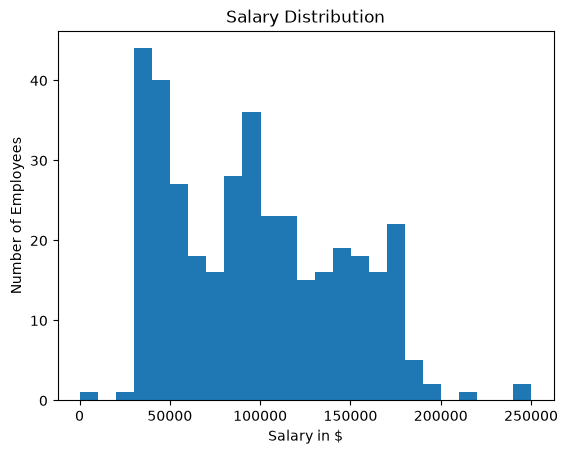

In [47]:
salary_hist_ax = df.plot.hist(column=["salary"], bins=25, legend=False)
salary_hist_ax.set_xlabel("Salary in $")
salary_hist_ax.set_ylabel("Number of Employees")
salary_hist_ax.set_title("Salary Distribution")
plt.show()

<a id='regression'></a>
#### Part II - Regression

`1.` Now that you have had a chance to learn more about the dataset, let's look more at how different factors are related to `salary`.

`a)` Consider average salary by gender, is there evidence that salaries are higher for one gender over the other?

In [48]:
df_gender_desc = df.groupby("gender")["salary"].describe()[["mean", "50%", "max"]]
df_gender_desc.style.format("${:.2f}")

,mean,50%,max
gender,,,
Female,$97011.17,$90000.00,$190000.00
Male,$103867.78,$97500.00,$250000.00


`b)` Consider average salary by education level, is there evidence that salaries are higher for increased education?

In [49]:
df_edu_desc = df.groupby("education_level")["salary"].describe()[["mean", "50%"]]
df_edu_desc.style.format("${:.2f}")

,mean,50%
education_level,,
Bachelor's,$74756.03,$65000.00
Master's,$129795.92,$120000.00
PhD,$157843.14,$155000.00


`c)` Consider average salary by years of experience, is there evidence that salaries are associated with increased years of experience?

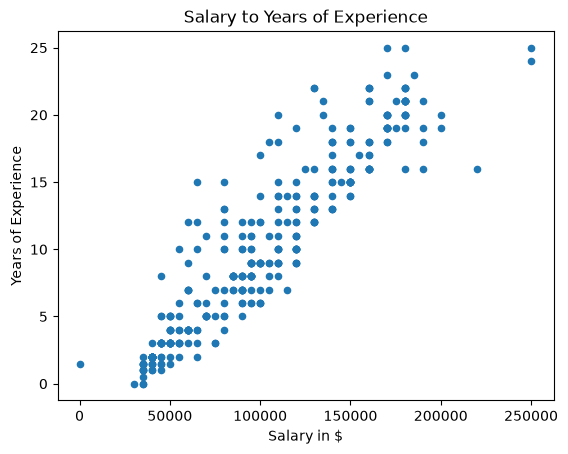

In [50]:
salary_to_exp_ax = df.plot.scatter(["salary"], ["years_experience"])
salary_to_exp_ax.set_xlabel("Salary in $")
salary_to_exp_ax.set_ylabel("Years of Experience")
salary_to_exp_ax.set_title("Salary to Years of Experience")
plt.show()

In [51]:
df["intercept"] = 1
salary_to_exp_model = sm.OLS(df["salary"], df[["intercept", "years_experience"]])
salary_to_exp_model_results = salary_to_exp_model.fit()
salary_to_exp_model_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 salary   R-squared:                       0.866
Model:                            OLS   Adj. R-squared:                  0.865
Method:                 Least Squares   F-statistic:                     2388.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          1.02e-163
Time:                        13:25:58   Log-Likelihood:                -4177.0
No. Observations:                 373   AIC:                             8358.
Df Residuals:                     371   BIC:                             8366.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
intercept         3.192e+04   1677.842     19.025      0.000    2.86e+04    3.52e+04
years_experience  6844.5105    140.065     48.867      0.000    6569.089    7119.932
==============================================================================
Omnibus:                       42.211   Durbin-Watson:                   1.862
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              119.478
Skew:                          -0.511   Prob(JB):                     1.14e-26
Kurtosis:                       5.577   Cond. No.                         22.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

`d)`  To make use of Job Title column lets create bool flag based on word existence


List of words:

* Director
* Junior
* Senior
* Manager
* Analyst
* Engineer

**This question is completed for you**

In [52]:
flag_words = ["director", "junior", "senior", "manager", "analyst", "engineer"]
df["job_title"] = df["job_title"].str.lower()
job_titles = []

for word in flag_words:
    job_title = "is_" + word
    df[job_title] = df["job_title"].str.contains(word)
    job_titles.append(job_title)

df = df.drop("job_title", axis=1)

In [53]:
# search for rows that did not match any of the job title flag words
no_job_title_flag = ~df[job_titles].any(axis=1)
print(
    f"{no_job_title_flag.sum()} of {len(df)} rows match none of the job title flag words"
)

46 of 373 rows match none of the job title flag words


`e)` Create a flag for gender where 1 is if a person is male and 0 if the person is not.

In [54]:
df = df.join(pd.get_dummies(df["gender"], dtype=int))
df.rename(columns={
    "Male": "male",
    "Female": "female"
}, inplace=True)

`f)` Use statsmodels to fit a linear model to predict salary using each of the features from `a-e`.  These include:
* Gender
* Job TItle
* Years of Experience
* Education

In [55]:
df = df.join(pd.get_dummies(df["education_level"], dtype=bool))
# adjust column names to make them easier to work with
df.rename(columns={
    "Bachelor's": "bachelors",
    "Master's": "masters",
    "PhD": "phd"
}, inplace=True)
df.head()

,age,gender,education_level,years_experience,salary,intercept,is_director,is_junior,is_senior,is_manager,is_analyst,is_engineer,female,male,bachelors,masters,phd
0,32.0,Male,Bachelor's,5.0,90000.0,1,False,False,False,False,False,True,0,1,True,False,False
1,28.0,Female,Master's,3.0,65000.0,1,False,False,False,False,True,False,1,0,False,True,False
2,45.0,Male,PhD,15.0,150000.0,1,False,False,True,True,False,False,0,1,False,False,True
3,36.0,Female,Bachelor's,7.0,60000.0,1,False,False,False,False,False,False,1,0,True,False,False
4,52.0,Male,Master's,20.0,200000.0,1,True,False,False,False,False,False,0,1,False,True,False


In [56]:
education_levels = ["bachelors", "masters", "phd"]

# verify baselines will represent a significant sample
# job_title will not have a baseline since the categorization was not exhaustive and therefore linearly independent
print(df.groupby(["gender"])["education_level"].value_counts())

gender_baseline = "female"
education_level_baseline = "bachelors"
education_levels.remove(education_level_baseline)
print(f"baseline columns: '{gender_baseline}', '{education_level_baseline}'")

predictors = (
    ["intercept", "male", "years_experience"] + education_levels + job_titles
)
print(f"predictors: {predictors}")

gender  education_level
Female  Bachelor's         103
        Master's            50
        PhD                 26
Male    Bachelor's         121
        Master's            48
        PhD                 25
Name: count, dtype: int64
baseline columns: 'female', 'bachelors'
predictors: ['intercept', 'male', 'years_experience', 'masters', 'phd', 'is_director', 'is_junior', 'is_senior', 'is_manager', 'is_analyst', 'is_engineer']


In [57]:
min_salary = df["salary"].min()
print(min_salary)
print(df.query("salary == @min_salary"))

# consider $350 as outlier and remove it from further analysis
df = df[df["salary"] > 350]

350.0
      age gender education_level  years_experience  salary  intercept  \
258  29.0   Male      Bachelor's               1.5   350.0          1   

     is_director  is_junior  is_senior  is_manager  is_analyst  is_engineer  \
258        False       True      False       False        True        False   

     female  male  bachelors  masters    phd  
258       0     1       True    False  False  


In [58]:
salary_model = sm.OLS(df["salary"], df[predictors])
salary_model_results = salary_model.fit()
salary_model_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 salary   R-squared:                       0.917
Model:                            OLS   Adj. R-squared:                  0.914
Method:                 Least Squares   F-statistic:                     396.3
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          7.55e-188
Time:                        13:26:32   Log-Likelihood:                -4075.5
No. Observations:                 372   AIC:                             8173.
Df Residuals:                     361   BIC:                             8216.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
intercept           3.2e+04   2458.521     13.014      0.000    2.72e+04    3.68e+04
male              7676.6582   1494.609      5.136      0.000    4737.424    1.06e+04
years_experience  4928.4788    195.393     25.223      0.000    4544.227    5312.730
masters           1.346e+04   2031.258      6.628      0.000    9468.287    1.75e+04
phd               2.338e+04   2771.286      8.436      0.000    1.79e+04    2.88e+04
is_director       2.554e+04   3496.600      7.305      0.000    1.87e+04    3.24e+04
is_junior        -4156.5912   2433.955     -1.708      0.089   -8943.104     629.921
is_senior         1.302e+04   1955.098      6.659      0.000    9174.774    1.69e+04
is_manager        4503.6322   1938.874      2.323      0.021     690.725    8316.539
is_analyst         406.1927   2089.609      0.194      0.846   -3703.142    4515.527
is_engineer       2371.1630   3522.702      0.673      0.501   -4556.433    9298.759
==============================================================================
Omnibus:                      141.271   Durbin-Watson:                   1.805
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1191.427
Skew:                           1.357   Prob(JB):                    1.93e-259
Kurtosis:                      11.337   Cond. No.                         63.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<a id='interpretation'></a>
### Part III - Interpret Results

`1.` Consider you are tasked with finding which features in your linear model are significantly related to salary.  Were there any features that were not significantly related to salary in your first model?  If not, remove those features and fit a new model.  Only keep the features that were significant from the original model.

In [59]:
# explain your answer and fit a new model with the reduced set of features here
print("omitting insignificant predictor variables (p-value > 0.05):")

for p, v in salary_model_results.pvalues.items():
    if p != "intercept" and v > 0.05:
        print(f"  {p:<15}{v:.4f}")
        predictors.remove(p)

salary_model = sm.OLS(df["salary"], df[predictors])
salary_model_results = salary_model.fit()
salary_model_results.summary()

omitting insignificant predictor variables (p-value > 0.05):
  is_junior      0.0885
  is_analyst     0.8460
  is_engineer    0.5013


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 salary   R-squared:                       0.916
Model:                            OLS   Adj. R-squared:                  0.914
Method:                 Least Squares   F-statistic:                     564.9
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          3.42e-191
Time:                        13:27:02   Log-Likelihood:                -4077.2
No. Observations:                 372   AIC:                             8170.
Df Residuals:                     364   BIC:                             8202.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
intercept         2.907e+04   1660.594     17.505      0.000    2.58e+04    3.23e+04
male              7848.8370   1466.075      5.354      0.000    4965.796    1.07e+04
years_experience  5081.2555    175.297     28.987      0.000    4736.533    5425.978
masters           1.397e+04   2008.268      6.958      0.000       1e+04    1.79e+04
phd               2.314e+04   2728.306      8.480      0.000    1.78e+04    2.85e+04
is_director       2.505e+04   3461.875      7.237      0.000    1.82e+04    3.19e+04
is_senior         1.435e+04   1799.292      7.973      0.000    1.08e+04    1.79e+04
is_manager        4174.9452   1801.474      2.318      0.021     632.342    7717.549
==============================================================================
Omnibus:                      136.767   Durbin-Watson:                   1.779
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1088.167
Skew:                           1.322   Prob(JB):                    5.10e-237
Kurtosis:                      10.951   Cond. No.                         60.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [64]:
model_coef = salary_model_results.params
model_conf_int = salary_model_results.conf_int()
standard_disclaimer = ", holding all other variables constant"

`a)` With each additional year of experience, what is the expected change in salary?  What is the 95% confidence interval of the change?

In [65]:
print("Answer:")
print(
    f"+ ${model_coef['years_experience']:.2f} per year of experience{standard_disclaimer}"
)
print(
    f"95% confidence interval: ${model_conf_int.loc['years_experience'][0]:.2f} - ${model_conf_int.loc['years_experience'][1]:.2f}"
)

Answer:
+ $5081.26 per year of experience, holding all other variables constant
95% confidence interval: $4736.53 - $5425.98


`b)` What is the expected difference in salary between someone with a senior title and someone with none of the other title indications?

In [66]:
print("Answer:")
print(f"+ ${model_coef['is_senior']:.2f}{standard_disclaimer}")

Answer:
+ $14345.60, holding all other variables constant


`c)` What is the expected difference in salary between someone with a PhD and an individual with no PhD nor master's degree?  What is the 95% confidence interval of the change?

In [67]:
print("Answer:")
print(
    f"+ ${model_coef['phd']:.2f}{standard_disclaimer}"
)
print(
    f"95% confidence interval: ${model_conf_int.loc['phd'][0]:.2f} - ${model_conf_int.loc['phd'][1]:.2f}"
)

Answer:
+ $23137.04, holding all other variables constant
95% confidence interval: $17771.82 - $28502.26


`d)` If a male employee has 5 years of experience as a senior engineer with a bachelor's degree, what is the expected salary of the employee?

In [68]:
male_5_senior_bachelor = model_coef["intercept"] + model_coef["male"] + (model_coef["years_experience"]*5) + model_coef["is_senior"]

print("Answer:")
print(f"expected salary: ${male_5_senior_bachelor:.2f}")

Answer:
expected salary: $76669.09


`e)` Imagine that the employee in question `d)` actually has a salary of $110,000, what would the residual be for this employee?

In [69]:
print("Answer:")
print(f"+ ${110000 - male_5_senior_bachelor:.2f}")

Answer:
+ $33330.91


`f)` How well do you think your model fits?  What metrics or plots would you consider to understand if this model does a good job of predicting salary?

In [70]:
### Your work here
print("Answer:")
print(f"R-squared: {(salary_model_results.rsquared):.4f}")

Answer:
R-squared: 0.9157


#### Question F Summary

The linear regression model of statistical associations between `male`, `years_experience`, `masters`, `is_director`, `is_senior`, and `is_manager` showed statistically significant associations with positive changes in `salary`. The R-squared result of model was `0.9157`, which indicates the model has significant explanatory power.

Evidence of multi-colinearities between some of the variables and `years_experience` was found, but their effect on the model wasn't sufficient to warrant excluding them.

##### "years_experience" Multi-Colinearities
Some of the variables in the model could have colinearities with "years_experience"

__Suspected Variables__

- `is_director`
- `is_senior`
- `is_manager`
- `masters`
- `phd`

These are violin plots that compare the `years_experience` distribution in relation to the suspected variables. Note that a True value in all but `is_manager` has a distribution that is noticeably shifted toward higher `years_experience` values.

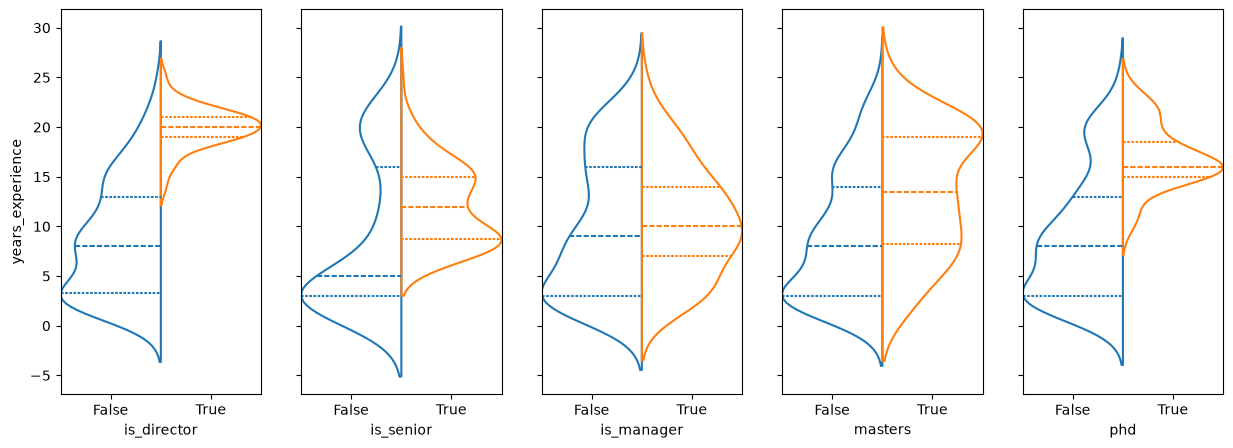

In [71]:
# violin plots of suspected variables (True vs False) and mean years_experience
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(1, 5, sharey=True, figsize=(15, 5))

sb.violinplot(
    data=df,
    x="is_director",
    y="years_experience",
    ax=ax1,
    fill=False,
    inner="quart",
    split=True,
    hue="is_director",
    legend=False,
    gap=0,
    width=1
)
sb.violinplot(
    data=df,
    x="is_senior",
    y="years_experience",
    ax=ax2,
    fill=False,
    inner="quart",
    split=True,
    hue="is_senior",
    legend=False,
    gap=0,
    width=1,
)
sb.violinplot(
    data=df,
    x="is_manager",
    y="years_experience",
    ax=ax3,
    fill=False,
    inner="quart",
    split=True,
    hue="is_manager",
    legend=False,
    gap=0,
    width=1,
)
sb.violinplot(
    data=df,
    x="masters",
    y="years_experience",
    ax=ax4,
    fill=False,
    inner="quart",
    split=True,
    hue="masters",
    legend=False,
    gap=0,
    width=1,
)
sb.violinplot(
    data=df,
    x="phd",
    y="years_experience",
    ax=ax5,
    fill=False,
    inner="quart",
    split=True,
    hue="phd",
    legend=False,
    gap=0,
    width=1,
)
plt.show()

__Linear Regression__

Running a linear regression model of experience and training level related variables to `years_experience` reveals statistically significant relationships. This is likely affecting the quality of the `salary` linear regression model results.

| suspected variable | coef | p-value |
| --- | --- | --- |
| `masters` | 2.6187 | 0.000 |
| `phd` | 7.2576 | 0.000 |
| `is_director` | 11.5747 | 0.000 |
| `is_senior` | 3.7267 | 0.000 |
| `is_manager` | 2.7672 | 0.000 |

R-squared: __0.595__

All have p-values of __0.000__ when used as predictor variables against `years_experience` and the regression as a whole returns an R-squared value of __0.595__ indicating these 5 predictor variables explain 59.5% of the variance of `years_experience` in the dataset.

The baseline for the `education_level` categorical `bachelors` is also likely correlated.

In [72]:
years_experience_colin_model = sm.OLS(df["years_experience"], df[["intercept", "is_director", "is_senior", "is_manager", "masters", "phd"]])
years_experience_colin_model_results = years_experience_colin_model.fit()
years_experience_colin_model_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       years_experience   R-squared:                       0.595
Model:                            OLS   Adj. R-squared:                  0.589
Method:                 Least Squares   F-statistic:                     107.4
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           1.41e-69
Time:                        13:33:08   Log-Likelihood:                -1058.5
No. Observations:                 372   AIC:                             2129.
Df Residuals:                     366   BIC:                             2153.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
intercept       4.8252      0.357     13.520      0.000       4.123       5.527
is_director    11.5747      0.836     13.840      0.000       9.930      13.219
is_senior       3.7267      0.500      7.454      0.000       2.744       4.710
is_manager      2.7672      0.517      5.349      0.000       1.750       3.785
masters         2.6187      0.582      4.501      0.000       1.475       3.763
phd             7.2576      0.719     10.093      0.000       5.844       8.672
==============================================================================
Omnibus:                      114.033   Durbin-Watson:                   2.176
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              308.397
Skew:                           1.457   Prob(JB):                     1.08e-67
Kurtosis:                       6.378   Cond. No.                         5.35
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

__Variance Inflation Factor Test__

None of the suspected variables meet the > 10 threshold which would suggest our model would be improved if we removed them.

In [74]:
y, X = dmatrices("salary ~ years_experience + is_director + is_senior + is_manager + masters + phd ", df, return_type="dataframe")
vif = pd.DataFrame()
vif["VIF Factor"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif["features"] = X.columns
vif

,VIF Factor,features
0,1.000000,Intercept
1,2.251962,is_director[T.True]
2,1.468272,is_senior[T.True]
3,1.166135,is_manager[T.True]
4,1.462968,masters[T.True]
5,1.650073,phd[T.True]
6,2.467718,years_experience


<a id='finalcheck'></a>
## Final Check!

Congratulations!  You have reached the end of the salary prediction project!  You should be very proud of all you have accomplished!

> **Tip**: Once you are satisfied with your work here, check over your notebook to make sure that it satisfies all the specifications mentioned in the rubric. You should also probably remove all of the "Hints" and "Tips" like this one so that the presentation is as polished as possible.


<a id='submission'></a>
## Submission

Please follow the directions in the classroom to submit this notebook, as well as your completed slides.